# Phase 3: Performance Benchmarking and Quantization

## Objective
Measure the inference performance of the Phase 1 MNIST model and evaluate the trade-offs of INT8 dynamic quantization.

## Experiments
1. Verify the original FP32 model
2. Measure single-image inference latency
3. Measure P50, P95, and P99 latency
4. Benchmark throughput across batch sizes
5. Quantize supported Linear layers to INT8
6. Compare accuracy, model size, latency, and throughput
7. Save benchmark results and charts

## Important
- Use the same test dataset for both models.
- Use CPU inference for both FP32 and INT8 comparisons.
- Run warm-up iterations before timing.
- Report measured results, not assumed performance gains.

In [39]:
import json
import random
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torchvision

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_PATH = PROJECT_ROOT / "models" / "mnist_baseline.pth"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Keep this phase CPU-focused for a fair FP32 vs INT8 comparison.
device = torch.device("cpu")
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CPU threads:", torch.get_num_threads())
print("Model exists:", MODEL_PATH.exists())

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

Python: 3.11.9
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
CPU threads: 2
Model exists: True


In [40]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model_fp32 = MNISTMLP().to(device)

state_dict = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=True
)

model_fp32.load_state_dict(state_dict)
model_fp32.eval()

parameter_count = sum(
    parameter.numel()
    for parameter in model_fp32.parameters()
    if parameter.requires_grad
)

print("FP32 model loaded.")
print("Trainable parameters:", parameter_count)

FP32 model loaded.
Trainable parameters: 109386


In [41]:
test_dataset = datasets.MNIST(
    root=str(PROJECT_ROOT / "data"),
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Test samples:", len(test_dataset))

Test samples: 10000


In [42]:
def evaluate_accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in loader:
            logits = model(images.to(device))
            predictions = logits.argmax(dim=1)

            correct += (predictions == labels.to(device)).sum().item()
            total += labels.size(0)

    return correct / total


def get_state_dict_size_mb(model, filename):
    path = REPORTS_DIR / filename
    torch.save(model.state_dict(), path)
    return path.stat().st_size / (1024 ** 2)


fp32_accuracy = evaluate_accuracy(model_fp32, test_loader)
fp32_size_mb = get_state_dict_size_mb(
    model_fp32, "benchmark_fp32_state_dict.pth"
)

print(f"FP32 test accuracy: {fp32_accuracy:.2%}")
print(f"FP32 state-dict size: {fp32_size_mb:.4f} MB")

FP32 test accuracy: 97.76%
FP32 state-dict size: 0.4205 MB


In [43]:
def benchmark_single_image_latency(model, warmup=50, repeats=500):
    model.eval()
    sample = test_dataset[0][0].unsqueeze(0).to(device)

    with torch.inference_mode():
        for _ in range(warmup):
            model(sample)

        timings_ms = []

        for _ in range(repeats):
            start = time.perf_counter()
            model(sample)
            elapsed_ms = (time.perf_counter() - start) * 1000
            timings_ms.append(elapsed_ms)

    return {
        "p50_ms": float(np.percentile(timings_ms, 50)),
        "p95_ms": float(np.percentile(timings_ms, 95)),
        "p99_ms": float(np.percentile(timings_ms, 99)),
        "mean_ms": float(np.mean(timings_ms)),
        "min_ms": float(np.min(timings_ms))
    }


fp32_latency = benchmark_single_image_latency(model_fp32)

print("FP32 single-image latency:")
for metric, value in fp32_latency.items():
    print(f"{metric}: {value:.4f}")

FP32 single-image latency:
p50_ms: 0.0927
p95_ms: 0.1663
p99_ms: 0.5187
mean_ms: 0.1137
min_ms: 0.0788


In [44]:
def benchmark_single_image_latency(model, warmup=50, repeats=500):
    model.eval()
    sample = test_dataset[0][0].unsqueeze(0).to(device)

    with torch.inference_mode():
        for _ in range(warmup):
            model(sample)

        timings_ms = []

        for _ in range(repeats):
            start = time.perf_counter()
            model(sample)
            elapsed_ms = (time.perf_counter() - start) * 1000
            timings_ms.append(elapsed_ms)

    return {
        "p50_ms": float(np.percentile(timings_ms, 50)),
        "p95_ms": float(np.percentile(timings_ms, 95)),
        "p99_ms": float(np.percentile(timings_ms, 99)),
        "mean_ms": float(np.mean(timings_ms)),
        "min_ms": float(np.min(timings_ms))
    }


fp32_latency = benchmark_single_image_latency(model_fp32)

print("FP32 single-image latency:")
for metric, value in fp32_latency.items():
    print(f"{metric}: {value:.4f}")

FP32 single-image latency:
p50_ms: 0.1262
p95_ms: 0.2666
p99_ms: 1.1005
mean_ms: 0.1527
min_ms: 0.0787


In [45]:
def benchmark_throughput(model, batch_sizes=(1, 8, 32, 128), repeats=100):
    model.eval()
    sample_images = test_dataset.data[:max(batch_sizes)].unsqueeze(1)
    sample_images = sample_images.float() / 255.0

    results = []

    with torch.inference_mode():
        for batch_size in batch_sizes:
            batch = sample_images[:batch_size].to(device)

            for _ in range(20):
                model(batch)

            start = time.perf_counter()
            for _ in range(repeats):
                model(batch)
            elapsed = time.perf_counter() - start

            images_processed = batch_size * repeats

            results.append({
                "batch_size": batch_size,
                "elapsed_seconds": elapsed,
                "images_processed": images_processed,
                "throughput_images_per_second": images_processed / elapsed,
                "average_batch_latency_ms": elapsed * 1000 / repeats
            })

    return pd.DataFrame(results)


fp32_throughput = benchmark_throughput(model_fp32)
display(fp32_throughput)

,batch_size,elapsed_seconds,images_processed,throughput_images_per_second,average_batch_latency_ms
0,1,0.012030,100,8312.206484,0.120305
1,8,0.017665,800,45288.060246,0.176647
2,32,0.023681,3200,135127.146230,0.236814
3,128,0.065315,12800,195974.860068,0.653145


In [46]:
model_int8 = torch.ao.quantization.quantize_dynamic(
    model_fp32,
    {nn.Linear},
    dtype=torch.qint8
)

model_int8.eval()

print("Dynamic INT8 quantization completed.")
print(model_int8)

Dynamic INT8 quantization completed.
MNISTMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): DynamicQuantizedLinear(in_features=784, out_features=128, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
    (2): ReLU()
    (3): DynamicQuantizedLinear(in_features=128, out_features=64, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): DynamicQuantizedLinear(in_features=64, out_features=10, dtype=torch.qint8, qscheme=torch.per_tensor_affine)
  )
)


C:\Users\admin\AppData\Local\Temp\ipykernel_13164\830572940.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  model_int8 = torch.ao.quantization.quantize_dynamic(


In [47]:
int8_accuracy = evaluate_accuracy(model_int8, test_loader)

print(f"FP32 accuracy: {fp32_accuracy:.2%}")
print(f"INT8 accuracy: {int8_accuracy:.2%}")
print(
    "Accuracy change: "
    f"{(int8_accuracy - fp32_accuracy) * 100:.3f} percentage points"
)

FP32 accuracy: 97.76%
INT8 accuracy: 97.83%
Accuracy change: 0.070 percentage points


In [48]:
int8_latency = benchmark_single_image_latency(model_int8)

int8_throughput = benchmark_throughput(model_int8)

int8_size_mb = get_state_dict_size_mb(
    model_int8, "benchmark_int8_state_dict.pth"
)

print("INT8 single-image latency:")
for metric, value in int8_latency.items():
    print(f"{metric}: {value:.4f}")

print(f"\nINT8 state-dict size: {int8_size_mb:.4f} MB")
display(int8_throughput)

INT8 single-image latency:
p50_ms: 0.6558
p95_ms: 1.1600
p99_ms: 2.1441
mean_ms: 0.6536
min_ms: 0.4245

INT8 state-dict size: 0.1102 MB


,batch_size,elapsed_seconds,images_processed,throughput_images_per_second,average_batch_latency_ms
0,1,0.064687,100,1545.912838,0.646867
1,8,0.079654,800,10043.400042,0.796543
2,32,0.070526,3200,45373.530504,0.705257
3,128,0.076228,12800,167917.741064,0.762278


In [49]:
comparison_df = pd.DataFrame([
    {
        "model": "FP32",
        "accuracy": fp32_accuracy,
        "size_mb": fp32_size_mb,
        "p50_latency_ms": fp32_latency["p50_ms"],
        "p95_latency_ms": fp32_latency["p95_ms"],
        "p99_latency_ms": fp32_latency["p99_ms"]
    },
    {
        "model": "INT8 dynamic",
        "accuracy": int8_accuracy,
        "size_mb": int8_size_mb,
        "p50_latency_ms": int8_latency["p50_ms"],
        "p95_latency_ms": int8_latency["p95_ms"],
        "p99_latency_ms": int8_latency["p99_ms"]
    }
])

display(comparison_df.style.format({
    "accuracy": "{:.2%}",
    "size_mb": "{:.4f}",
    "p50_latency_ms": "{:.4f}",
    "p95_latency_ms": "{:.4f}",
    "p99_latency_ms": "{:.4f}"
}))

,model,accuracy,size_mb,p50_latency_ms,p95_latency_ms,p99_latency_ms
0,FP32,97.76%,0.4205,0.1262,0.2666,1.1005
1,INT8 dynamic,97.83%,0.1102,0.6558,1.1600,2.1441


In [50]:
size_reduction_pct = (
    (fp32_size_mb - int8_size_mb) / fp32_size_mb * 100
    if fp32_size_mb > 0 else 0
)

p50_improvement_pct = (
    (fp32_latency["p50_ms"] - int8_latency["p50_ms"])
    / fp32_latency["p50_ms"] * 100
    if fp32_latency["p50_ms"] > 0 else 0
)

accuracy_change_pp = (int8_accuracy - fp32_accuracy) * 100

print(f"State-dict size reduction: {size_reduction_pct:.2f}%")
print(f"P50 latency improvement: {p50_improvement_pct:.2f}%")
print(f"Accuracy change: {accuracy_change_pp:.3f} percentage points")

State-dict size reduction: 73.80%
P50 latency improvement: -419.61%
Accuracy change: 0.070 percentage points


In [51]:
throughput_comparison_df = pd.concat([
    fp32_throughput.assign(model="FP32"),
    int8_throughput.assign(model="INT8 dynamic")
], ignore_index=True)

display(throughput_comparison_df)

,batch_size,elapsed_seconds,images_processed,throughput_images_per_second,average_batch_latency_ms,model
0,1,0.012030,100,8312.206484,0.120305,FP32
1,8,0.017665,800,45288.060246,0.176647,FP32
2,32,0.023681,3200,135127.146230,0.236814,FP32
3,128,0.065315,12800,195974.860068,0.653145,FP32
4,1,0.064687,100,1545.912838,0.646867,INT8 dynamic
5,8,0.079654,800,10043.400042,0.796543,INT8 dynamic
6,32,0.070526,3200,45373.530504,0.705257,INT8 dynamic
7,128,0.076228,12800,167917.741064,0.762278,INT8 dynamic


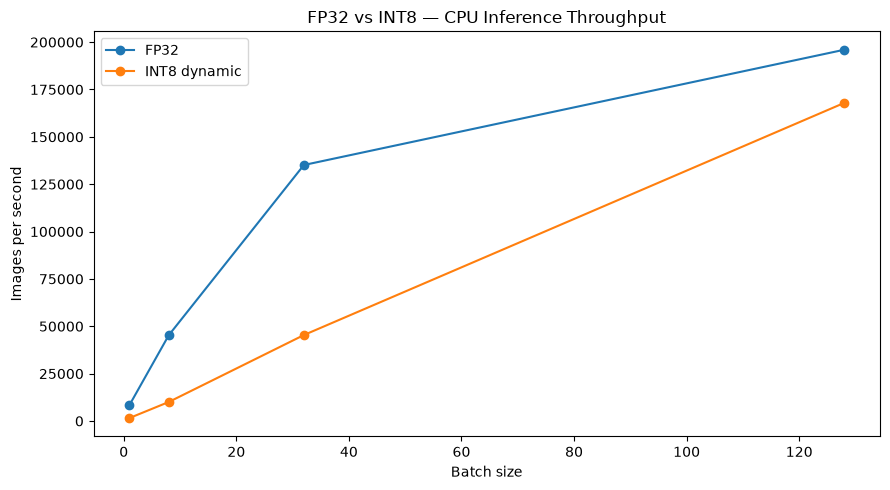

In [52]:
plt.figure(figsize=(9, 5))

for model_name, group in throughput_comparison_df.groupby("model"):
    plt.plot(
        group["batch_size"],
        group["throughput_images_per_second"],
        marker="o",
        label=model_name
    )

plt.xlabel("Batch size")
plt.ylabel("Images per second")
plt.title("FP32 vs INT8 — CPU Inference Throughput")
plt.legend()
plt.tight_layout()

throughput_chart_path = REPORTS_DIR / "phase3_throughput_comparison.png"
plt.savefig(throughput_chart_path, dpi=150, bbox_inches="tight")
plt.show()

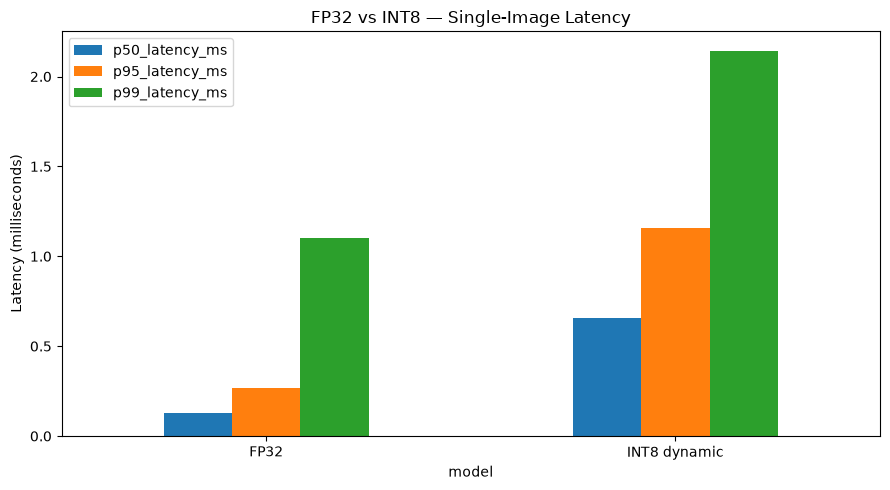

In [53]:
latency_metrics = ["p50_latency_ms", "p95_latency_ms", "p99_latency_ms"]

latency_plot_df = comparison_df.set_index("model")[latency_metrics]

ax = latency_plot_df.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("Latency (milliseconds)")
ax.set_title("FP32 vs INT8 — Single-Image Latency")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

latency_chart_path = REPORTS_DIR / "phase3_latency_comparison.png"
plt.savefig(latency_chart_path, dpi=150, bbox_inches="tight")
plt.show()

In [54]:
comparison_df.to_csv(
    REPORTS_DIR / "phase3_model_comparison.csv",
    index=False
)

throughput_comparison_df.to_csv(
    REPORTS_DIR / "phase3_throughput.csv",
    index=False
)

benchmark_report = {
    "experiment": "Phase 3 - Performance Benchmarking and Quantization",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": "CPU",
    "cpu_threads": torch.get_num_threads(),
    "test_samples": len(test_dataset),
    "batch_sizes": [1, 8, 32, 128],
    "latency_repeats": 500,
    "throughput_repeats": 100,
    "results": comparison_df.to_dict(orient="records"),
    "throughput": throughput_comparison_df.to_dict(orient="records"),
    "notes": [
        "Latency is measured for model inference without API or network overhead.",
        "Model size represents the serialized state dictionary.",
        "INT8 uses PyTorch dynamic quantization of supported Linear layers.",
        "Performance results depend on hardware and runtime conditions."
    ]
}

with open(
    REPORTS_DIR / "phase3_benchmark_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(benchmark_report, file, indent=2)

print("Benchmark reports saved.")

Benchmark reports saved.


In [55]:
summary_lines = [
    "# Phase 3: Performance Benchmarking and Quantization",
    "",
    f"Generated (UTC): {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Results",
    "",
    "| Model | Accuracy | State-dict size (MB) | P50 (ms) | P95 (ms) | P99 (ms) |",
    "|---|---:|---:|---:|---:|---:|"
]

for _, row in comparison_df.iterrows():
    summary_lines.append(
        f"| {row['model']} | {row['accuracy']:.2%} | "
        f"{row['size_mb']:.4f} | {row['p50_latency_ms']:.4f} | "
        f"{row['p95_latency_ms']:.4f} | {row['p99_latency_ms']:.4f} |"
    )

summary_lines += [
    "",
    "## Interpretation",
    "",
    f"- State-dict size change: {size_reduction_pct:.2f}% reduction.",
    f"- P50 latency improvement: {p50_improvement_pct:.2f}%.",
    f"- Accuracy change: {accuracy_change_pp:.3f} percentage points.",
    "",
    "## Limitations",
    "- Results are local CPU microbenchmarks.",
    "- They exclude API, networking, and deployment overhead.",
    "- Performance can vary with system load and hardware.",
    "- Quantization benefits must be verified empirically."
]

summary_path = REPORTS_DIR / "phase3_benchmark_report.md"
summary_path.write_text("\n".join(summary_lines), encoding="utf-8")

print("Saved:", summary_path)

Saved: c:\vathsan\BITS\ai-quality-engineering-mnist-digit-recognition-project\reports\phase3_benchmark_report.md


In [56]:
expected_files = [
    "phase3_model_comparison.csv",
    "phase3_throughput.csv",
    "phase3_benchmark_metrics.json",
    "phase3_latency_comparison.png",
    "phase3_throughput_comparison.png",
    "phase3_benchmark_report.md"
]

for filename in expected_files:
    path = REPORTS_DIR / filename
    print(f"{'OK' if path.exists() else 'MISSING'}: {filename}")

OK: phase3_model_comparison.csv
OK: phase3_throughput.csv
OK: phase3_benchmark_metrics.json
OK: phase3_latency_comparison.png
OK: phase3_throughput_comparison.png
OK: phase3_benchmark_report.md


## Phase 3: Performance Benchmarking and Quantization

**Status:** Implemented locally; results pending verification.

Experiments:
- Single-image inference latency (P50/P95/P99)
- Throughput across batch sizes
- CPU FP32 versus dynamic INT8 quantization
- Model accuracy and serialized state-dictionary size comparison

Generated artifacts:
- `reports/phase3_model_comparison.csv`
- `reports/phase3_throughput.csv`
- `reports/phase3_benchmark_metrics.json`
- `reports/phase3_latency_comparison.png`
- `reports/phase3_throughput_comparison.png`
- `reports/phase3_benchmark_report.md`

The reported measurements are local CPU microbenchmarks, not end-to-end production service metrics.
